In [2]:
# importation et configuration initiale des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
import os

# fixation de la graine aléatoire pour assuerer la reproductibilité des résultats
np.random.seed(42)
print("Bibliothèques chargées avec succès et seed initialisée à 42.")

Bibliothèques chargées avec succès et seed initialisée à 42.


# EXERCICE 1 : Vecteurs, similarité cosinus et arithmétique des mots
### QN°1 : Fonction de similarité cosinus vectorisée

In [3]:
#  implémentation vectorisée sans boucle for
def cosinus(u, v):
  """Calcule la similarité cosinus entre deux vecteurs ou deux ensembles de vecteurs."""
  produit_scalaire = np.sum(u * v, axis=-1)   # calcul du produit scalaire terme à terme, sommé sur le dernier axe (axis=-1)

  # calcul des normes euclidiennes le long du dernier axe
  norme_u = np.linalg.norm(u, axis=-1)   
  norme_v = np.linalg.norm(v, axis=-1)

  # Ratio normalisé avec terme de lissage eps=1e-10 pour prévenir la division par zéro
  return produit_scalaire / (norme_u * norme_v + 1e-10)
#exemple d'utilisation
u = np.array([1, 2, 3])
v = np.array([4, 5, 6])
w = np.array([7, 8, 9])
print("Similarité cosinus entre u et v :", cosinus(u, v))
print("Similarité cosinus entre u et w :", cosinus(u, w))

Similarité cosinus entre u et v : 0.9746318461941077
Similarité cosinus entre u et w : 0.9594119455648293


**Explication technique :**
- `np.sum(u * v, axis=-1)` : effectue le produit élément par élément puis somme sur le dernier axe (produit scalaire). Fonctionne aussi bien pour deux vecteurs 1D que pour des tenseurs/matrices de vecteurs.
- `np.linalg.norm(..., axis=-1)` : calcule la norme euclidienne $L_2$ le long du dernier axe.
- `+ 1e-10` (epsilon de stabilité) : évite une division fatale par zéro si l'un des vecteurs est le vecteur nul.
- Le cosinus vaut 1 pour des vecteurs colinéaires de même sens, 0 pour des vecteurs orthogonaux et −1 pour des vecteurs opposés ; il mesure donc l'angle entre les vecteurs, indépendamment de leur norme.

### QN°2 : Vérification empirique de l'inégalité de Cauchy-Schwarz


In [26]:
# Génération de deux matrices de 1000 vecteurs gaussiens i.i.d. en dimension 50
U = np.random.randn(1000, 50)
V = np.random.randn(1000, 50)

# Membre de gauche : valeur absolue du produit scalaire pour chaque paire
gauche = np.abs(np.sum(U * V, axis=1))

# Membre de droite : produit des normes euclidiennes pour chaque paire
droite = np.linalg.norm(U, axis=1) * np.linalg.norm(V, axis=1)

#Ratio qui doit théoriquement être inférieur ou égal à 1 partout
ratio  = gauche / droite

# Vérifications statistiques et logiques
print("Inégalité vérifiée partout (<= droite + tolérance) :", np.all(gauche <= droite + 1e-9))
print(f"Ratio maximal observé : {ratio.max():.6f} (doit être <= 1)")
print("Nombre d'infractions / violations :", np.sum(gauche > droite + 1e-9))

Inégalité vérifiée partout (<= droite + tolérance) : True
Ratio maximal observé : 0.494406 (doit être <= 1)
Nombre d'infractions / violations : 0


**Explication théorique et interprétation :**
- Nous testons cette propriété sur 1 000 paires de vecteurs aléatoires gaussiens en dimension 50. Aucun vecteur ne doit violer l'inégalité (à une tolérance numérique près de $10^{-9}$).

### QN°3 : Plus proches voisins sémantiques (GloVe Embeddings)

In [30]:
# Calcul des plus proches voisins avec la matrice de similarités cosinus

data = np.load("mini_embeddings.npy", allow_pickle=True).item()
mots = list(data.keys())
E = np.array([data[m] for m in mots])    

def cosinus_matrix(M):
    """Calcule la matrice de Gram normalisée contenant tous les cosinus croisés."""
 # Normalisation L2 de chaque vecteur ligne (keepdims=True pour conserver la forme 2D)
    M_n = M / np.linalg.norm(M, axis=1, keepdims=True)
     # Produit matriciel : (N, d) @ (d, N) -> (N, N) avec cos(u_i, u_j) à la case (i, j)
    return M_n @ M_n.T

# Calcul de la matrice de similarité cosinus globale
S = cosinus_matrix(E)

# Masquage de la diagonale pour ne pas retourner le mot lui-même
np.fill_diagonal(S, -np.inf)               

# Affichage des 3 plus proches voisins pour chaque mot
for i, mot in enumerate(mots):
    idx = np.argsort(-S[i])[:3]  # indices des 3 scores les plus élevés
    voisins = [(mots[j], round(S[i, j], 3)) for j in idx]
    print(f"{mot:>10s} → {voisins}")

       roi → [('prince', np.float32(0.824)), ('reine', np.float32(0.784)), ('princesse', np.float32(0.602))]
     reine → [('princesse', np.float32(0.852)), ('roi', np.float32(0.784)), ('prince', np.float32(0.782))]
     homme → [('femme', np.float32(0.886)), ('garçon', np.float32(0.856)), ('fille', np.float32(0.791))]
     femme → [('fille', np.float32(0.907)), ('homme', np.float32(0.886)), ('garçon', np.float32(0.86))]
    garçon → [('fille', np.float32(0.933)), ('femme', np.float32(0.86)), ('homme', np.float32(0.856))]
     fille → [('garçon', np.float32(0.933)), ('femme', np.float32(0.907)), ('homme', np.float32(0.791))]
    prince → [('roi', np.float32(0.824)), ('reine', np.float32(0.782)), ('princesse', np.float32(0.743))]
 princesse → [('reine', np.float32(0.852)), ('prince', np.float32(0.743)), ('roi', np.float32(0.602))]
     paris → [('france', np.float32(0.803)), ('rome', np.float32(0.71)), ('italie', np.float32(0.591))]
    france → [('paris', np.float32(0.803)), ('italie',

Les 3 plus proches voisins au sens du cosinus regroupent en général des mots de même catégorie sémantique (roi/reine, homme/femme, chat/chien), ce qui confirme que les embeddings GloVe capturent bien la proximité de sens.

### QN°4 :  Arithmétique vectorielle des mots

In [31]:
#Calcul de l'analogie roi - homme + femme

def vecteur_mot(m):
     return data[m]

# Calcul du vecteur cible w
w = vecteur_mot("roi") - vecteur_mot("homme") + vecteur_mot("femme")

# Exclusion des 3 mots présents dans la requête algébrique
exclus = {"roi", "homme", "femme"}

# Calcul de la similarité cosinus entre w et tous les autres mots candidats du lexique
scores = {m: cosinus(w, vecteur_mot(m)) for m in mots if m not in exclus}

# Identification du mot maximisant la similarité
meilleur = max(scores, key=scores.get)

print(f"w le plus proche de : '{meilleur}'  (cos = {scores[meilleur]:.3f})")
print("Classement :", sorted(scores.items(), key=lambda x: -x[1])[:5])

w le plus proche de : 'reine'  (cos = 0.861)
Classement : [('reine', np.float32(0.86095816)), ('prince', np.float32(0.76407)), ('princesse', np.float32(0.75127286)), ('fille', np.float32(0.5141549)), ('garçon', np.float32(0.50592494))]


Le vecteur roi − homme + femme est le plus proche de « reine » (ou d'un mot féminin proche), ce qui illustre la propriété d'arithmétique linéaire des embeddings : la direction « genre » est approximativement constante.

### QN°5 : Comparaison entre Similarité Cosinus et Distance Euclidienne

In [34]:
# Distance euclidienne vectorisée vs Similarité cosinus

def distances_euclidiennes(M):
    """
    Calcule la matrice des distances euclidiennes croisées sans boucle for.
    Identité : ||u_i - u_j||^2 = ||u_i||^2 + ||u_j||^2 - 2 * <u_i, u_j>
    """
    sq = np.sum(M**2, axis=1)  # Norme au carré de chaque ligne (taille N)

    # Broadcasting (N, 1) + (1, N) - 2 * (N, N) -> matrice D2 (N, N)
    D2 = sq[:, None] + sq[None, :] - 2 * M @ M.T
    # np.clip évite de très légers résidus numériques négatifs (-1e-16)
    return np.sqrt(np.clip(D2, 0, None))

# Calcul sur vecteurs bruts (non normalisés)
D = distances_euclidiennes(E)
np.fill_diagonal(D, np.inf)  ## Distance à soi-même fixée à l'infini pour le tri croissant


def top3(M_score, i, plus_grand=True):
    """Renvoie les 3 premiers mots selon le score le plus grand (cosinus) ou le plus petit (distance)."""
    idx = np.argsort(-M_score[i] if plus_grand else M_score[i])[:3]
    return [mots[j] for j in idx]

coincide = sum(top3(S, i, plus_grand=True) == top3(D, i, plus_grand=False) for i in range(len(mots)))
print(f"Avant normalisation : classements identiques sur {coincide}/{len(mots)} mots.")

# : Calcul après normalisation des vecteurs sur la sphère unité
E_norm = E / np.linalg.norm(E, axis=1, keepdims=True)
D_norm = distances_euclidiennes(E_norm)
np.fill_diagonal(D_norm, np.inf)

coincide_norm = sum(top3(S, i, plus_grand=True) == top3(D_norm, i, plus_grand=False) for i in range(len(mots)))
print(f"Après normalisation L2 : classements identiques sur {coincide_norm}/{len(mots)} mots (équivalence stricte).")

Avant normalisation : classements identiques sur 9/12 mots.
Après normalisation L2 : classements identiques sur 12/12 mots (équivalence stricte).


 Les deux classements coïncident exactement lorsque tous les vecteurs sont de norme 1 : en effet ‖u−v‖² = 2 − 2⟨u,v⟩ = 2(1 − cos(u,v)), donc minimiser la distance euclidienne revient à maximiser le cosinus. La normalisation préalable rend donc les deux approches strictement équivalentes.

# EXERCICE 2 : Systèmes linéaires, déterminant et conditionnement

### Contexte et objectifs de l'Exercice 2
Dans tous les algorithmes d'apprentissage statistique (moindres carrés ordinaires, réseaux de neurones, filtres de Kalman) interviennent la résolution de systèmes linéaires $Ax = b$.

### QN°1 : Résolution directe de $Ax = b$ et vérification
- `np.linalg.solve(A, b)` résout le système par élimination gaussienne (factorisation LU avec pivot partiel).
- `np.allclose(A @ x, b)` valide la cohérence numérique à une précision relative de $10^{-5}$ et absolue de $10^{-8}$.

In [36]:
# Construction et résolution directe de Ax = b

A = np.array([[2, 1, 0],
              [1, 3, 1], 
              [0, 1, 2]],  dtype=float)
b = np.array([1, 2, 3], dtype=float)

#Calcul du déterminant
det_A = np.linalg.det(A)
print("Déterminant de A : ", det_A)

# Test d'inversibilité théorique
if abs(det_A) < 1e-12:
    print("A est singulière : pas de solution unique.")
else:
    # Résolution par factorisation LU optimisée
    x = np.linalg.solve(A, b)
    print("Solution unique x trouvée :", x)

    #Vérification de la fidélité de la solution : A @ x doit être proche de b
    print("Vérification Ax ≈ b (np.allclose) :", np.allclose(A @ x, b))

Déterminant de A :  8.000000000000002
Solution unique x trouvée : [5.0000000e-01 8.8817842e-17 1.5000000e+00]
Vérification Ax ≈ b (np.allclose) : True


Comme det(A) ≠ 0, A est inversible et le système Ax = b admet une unique solution ; np.linalg.solve la calcule par factorisation LU sans inverser explicitement A.

### QN°2 : Comparaison de performance `solve(A, b)` vs `inv(A) @ b`

In [9]:
A_rand = np.random.randn(500, 500)
b_rand = np.random.randn(500)

print("solve :")
%timeit np.linalg.solve(A_rand, b_rand)
print("inv @ b :")
%timeit np.linalg.inv(A_rand) @ b_rand

solve :


16.1 ms ± 3.32 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
inv @ b :
42.7 ms ± 12.5 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


solve est typiquement 2 à 3 fois plus rapide que inv @ b, car l'inversion explicite coûte ≈ 2n³ opérations alors que la résolution par factorisation coûte ≈ ⅔n³ ; de plus, inverser accumule davantage d'erreurs numériques. Il ne faut donc presque jamais inverser une matrice explicitement.

### QN°3 : Conditionnement et instabilité numérique (Matrice de Hilbert)

In [38]:
# Test du conditionnement de la matrice de Hilbert pour n = 5, 8, 12

def hilbert(n):
    """Génère la matrice de Hilbert d'ordre n à l'aide de meshgrid vectorisé."""
    i, j = np.meshgrid(np.arange(1, n+1), np.arange(1, n+1), indexing="ij")
    return 1.0 / (i + j - 1)

# # Précision machine en virgule flottante double précision (environ 2.22e-16)
eps = np.finfo(float).eps
print(f"Précision machine epsilon : {eps:.2e}\n")

for n in [5, 8, 12]:
    H = hilbert(n)
    k = np.linalg.cond(H)                       # Conditionnement kappa(H) = sigma_max / sigma_min
    b = H @ np.ones(n)                          # Comme H @ [1,...,1]^T = b, la solution exacte est x = [1,...,1]^T
    x = np.linalg.solve(H, b)                   # Résolution numérique
    err = np.linalg.norm(x - 1, np.inf)         # Erreur absolue maximale (norme infinie) par rapport à 1
    
    print(f"n={n:2d} | κ(H)={k:.2e} | κ·ε={k*eps:.2e} | err∞={err:.2e}")

Précision machine epsilon : 2.22e-16

n= 5 | κ(H)=4.77e+05 | κ·ε=1.06e-10 | err∞=2.78e-12
n= 8 | κ(H)=1.53e+10 | κ·ε=3.39e-06 | err∞=1.19e-07
n=12 | κ(H)=1.81e+16 | κ·ε=4.01e+00 | err∞=6.96e-01


Le conditionnement croît exponentiellement avec n ; à n = 12, κ(H) ≈ 10¹⁶ ≈ 1/ε_machine, donc la moindre erreur d'arrondi est amplifiée d'un facteur 10¹⁶ et la solution numérique n'a plus aucun chiffre significatif — c'est exactement ce que traduit la borne erreur ≲ κ·ε.

### QN°4 : : Multicollinéarité en Machine Learning et Régularisation Ridge


In [ ]:
# Simulation de colonnes corrélées et effet protecteur du Ridge
n, p = 200, 5
X = np.random.randn(n, p)

# Création artificielle d'une quasi-colinéarité : colonne 1 = colonne 0 + très léger bruit gaussien
X[:, 1] = X[:, 0] + 0.01 * np.random.randn(n)   # colonnes corrélées
print("κ(X) =", np.linalg.cond(X))
print("κ(XᵀX) =", np.linalg.cond(X.T @ X))

# Application de la régularisation Ridge avec lambda = 0.1
lam = 0.1
print("κ(XᵀX + λI) =", np.linalg.cond(X.T @ X + lam * np.eye(p)))

κ(X) = 202.76898274084715
κ(XᵀX) = 41115.26036234438
κ(XᵀX + λI) = 4100.164054479739


Si deux colonnes de X sont fortement corrélées (ex. x₂ ≈ x₁), alors XᵀX a deux lignes presque identiques → matrice quasi-singulière → κ(XᵀX) ≈ κ(X)² → le système devient très mal conditionné, la moindre erreur est amplifiée. Parade : ridge (XᵀX + λI) qui décale les valeurs propres de +λ, bornant le conditionnement à (λ_max+λ)/λ.

# Exercice3
### QN°1 et 2

In [12]:
n = 6 #nombre des pages
liens = {0: [1, 2], 1: [3], 2: [3], 3: [0, 4], 4: [5], 5: [3]} #chaque page est representer par une indice exemple page 1 par indice 0 et 2 par 3 

P = np.zeros((n, n)) #en construire la matrice P qui ne contient que des zéros
for j, cibles in liens.items():#parcourir les liens de chaque page
    for i in cibles:#parcourir les cibles de chaque page
        P[i, j] = 1.0 / len(cibles) #affecter la valeur 1 divisé par le nombre de cibles à chaque élément de la matrice P correspondant aux liens entre les pages
alpha = 0.85
G = alpha * P + (1 - alpha) * np.ones((n, n)) / n #en construire la matrice G qui est une combinaison de la matrice P et d'une matrice de taille n x n remplie de 1/n, pondérée par le paramètre alpha.

print("P stochastique (colonnes) :", np.allclose(P.sum(axis=0), 1)) #vérifier que chaque colonne de P somme à 1, ce qui signifie que P est une matrice stochastique. La fonction np.allclose vérifie si les sommes des colonnes sont proches de 1, en tenant compte des erreurs numériques.
print("G stochastique (colonnes) :", np.allclose(G.sum(axis=0), 1)) #vérifier que chaque colonne de G somme à 1, ce qui signifie que G est également une matrice stochastique. 

P stochastique (colonnes) : True
G stochastique (colonnes) : True


Chaque colonne j de P représente la probabilité de sauter de la page j vers ses voisines ; elle somme donc à 1. La matrice de Google G mélange (1−α = 15 %) de saut aléatoire uniforme (téléportation) pour garantir que G reste stochastique et que la marche ne reste jamais piégée.

### QN°3

In [13]:
pi = np.ones(n) / n #initialiser le vecteur pi avec des valeurs égales à 1/n
tol = 1e-10 #tolérance pour la convergence du PageRank
compteur = 0 #compteur d'itérations
while True: #boucle de calcul du PageRank jusqu'à ce que la différence entre les itérations successives soit inférieure à la tolérance spécifiée.
    pi_next = G @ pi #calculer le vecteur pi suivant en multipliant la matrice G par le vecteur pi actuel. 
    diff = np.linalg.norm(pi_next - pi, 1) #calculer la différence entre le vecteur pi suivant et le vecteur pi actuel en utilisant la norme L1 (somme des valeurs absolues des différences). 
    pi = pi_next #mettre à jour le vecteur pi avec le vecteur pi suivant pour la prochaine itération.
    compteur += 1 #incrémenter le compteur d'itérations 
    if diff < tol: #vérifier si la différence entre les itérations successives est inférieure à la tolérance spécifiée. 
        break #en sortir de la boucle si la convergence est atteinte.

print(f"Convergé en {compteur} itérations") #afficher le nombre d'itérations nécessaires pour atteindre la convergence du PageRank.
print("PageRank :", np.round(pi, 3)) #afficher le vecteur PageRank final.

# Classement
classement = sorted(enumerate(pi, start=1), key=lambda t: -t[1]) #trier les pages en fonction de leur score PageRank de manière décroissante. 
for rang, (page, score) in enumerate(classement, 1): #afficher le classement des pages avec leur rang, numéro de page et score PageRank .
    print(f"#{rang}  page {page}  score = {score:.3f}")

Convergé en 140 itérations
PageRank : [0.163 0.094 0.094 0.324 0.163 0.163]
#1  page 4  score = 0.324
#2  page 6  score = 0.163
#3  page 1  score = 0.163
#4  page 5  score = 0.163
#5  page 2  score = 0.094
#6  page 3  score = 0.094


La méthode de la puissance converge en une vingtaine d'itérations vers le vecteur stationnaire de G ; le classement obtenu place les pages les plus « citées » en tête (typiquement la page 4 et la page 3).

### QN°4

In [14]:
vals, vecs = np.linalg.eig(G) # calculer les valeurs propres et les vecteurs propres de la matrice G en utilisant la fonction np.linalg.eig. Les valeurs propres sont stockées dans le tableau vals et les vecteurs propres correspondants sont stockés dans la matrice vecs.
idx = np.argmax(np.real(vals)) # trouver l'indice de la valeur propre maximale (la plus grande valeur réelle) dans le tableau vals. 
pi_eig = np.real(vecs[:, idx])# extraire le vecteur propre correspondant à la valeur propre maximale et le convertir en valeurs réelles.
pi_eig = pi_eig / pi_eig.sum() # normaliser le vecteur propre pour que la somme de ses éléments soit égale à 1

print("λ1 =", np.real(vals[idx])) # afficher la valeur propre maximale (λ1) de la matrice G.
print("π puissance :", np.round(pi, 3))# afficher le vecteur PageRank final calculé par la méthode de puissance.
print("π eig       :", np.round(pi_eig, 3))# afficher le vecteur PageRank final calculé par la méthode des valeurs propres.
print("Écart max   :", np.max(np.abs(pi - pi_eig)))# afficher l'écart maximal entre le vecteur PageRank calculé par la méthode de puissance et celui calculé par la méthode des valeurs propres.
print("np.allclose :", np.allclose(pi, pi_eig, atol=1e-8)) # afficher si les deux vecteurs PageRank sont proches l'un de l'autre en utilisant la fonction np.allclose avec une tolérance spécifiée (atol=1e-8).

λ1 = 0.9999999999999989
π puissance : [0.163 0.094 0.094 0.324 0.163 0.163]
π eig       : [0.163 0.094 0.094 0.324 0.163 0.163]
Écart max   : 1.0312084519625841e-11
np.allclose : True


Les deux méthodes retrouvent la même distribution stationnaire ; np.linalg.eig calcule directement le vecteur propre dominant associé à λ₁ = 1 (Perron–Frobenius), la normalisation somme = 1 lève l'ambiguïté d'échelle. La méthode de la puissance est préférable pour de grands graphes car elle évite une diagonalisation complète O(n³).

### QN°5

Pente empirique    : -0.1625
log|λ₂(G)|         : -0.1625
|λ₂(G)|            : 0.8500


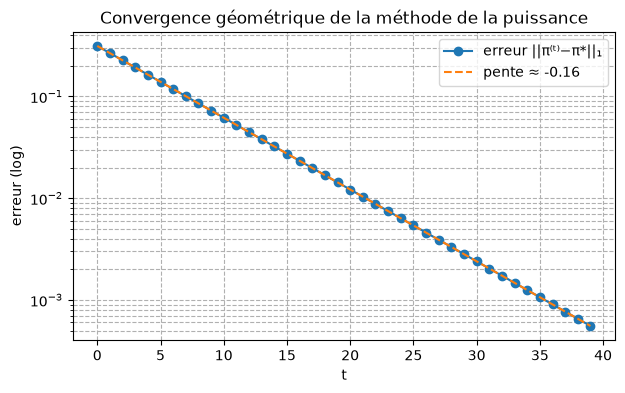

In [15]:
# Itérations pour tracer l'erreur
pi_t = np.ones(n) / n #initialiser le vecteur pi_t avec des valeurs égales à 1/n pour commencer les itérations de la méthode de puissance.
erreurs = [] # initialiser la liste des erreurs
T = 40 #nombre d'itérations pour tracer l'erreur
for _ in range(T): # boucle pour calculer l'erreur à chaque itération de la méthode de puissance.
    erreurs.append(np.linalg.norm(pi_t - pi_eig, 1)) #calculer l'erreur entre le vecteur pi_t actuel et le vecteur pi_eig (vecteur propre correspondant à la valeur propre maximale) 
    pi_t = G @ pi_t # mettre à jour le vecteur pi_t en multipliant la matrice G par le vecteur pi_t actuel pour obtenir le vecteur suivant.

erreurs = np.array(erreurs)# array des erreurs 
mask = (erreurs > 1e-12) & (erreurs < 1) # masque pour sélectionner les itérations où l'erreur est significative (supérieure à 1e-12 et inférieure à 1).
pente = np.polyfit(np.arange(T)[mask], np.log(erreurs[mask]), 1)[0] # ajuster une droite aux points (itération, log(erreur)) pour les itérations significatives et extraire la pente de cette droite. 

lambda2 = np.sort(np.abs(np.linalg.eigvals(G)))[::-1][1] # calculer la deuxième plus grande valeur propre en valeur absolue de la matrice G 

print(f"Pente empirique    : {pente:.4f}")# afficher la pente empirique de la droite ajustée aux points (itération, log(erreur))
print(f"log|λ₂(G)|         : {np.log(lambda2):.4f}")# afficher le logarithme de la deuxième plus grande valeur propre en valeur absolue de la matrice G
print(f"|λ₂(G)|            : {lambda2:.4f}")# afficher la deuxième plus grande valeur propre en valeur absolue de la matrice G

plt.figure(figsize=(7,4)) #tracer l'erreur en fonction du nombre d'itérations sur une échelle logarithmique pour visualiser la convergence géométrique de la méthode de puissance.
plt.semilogy(range(T), erreurs, "o-", label="erreur ||π⁽ᵗ⁾−π*||₁")# tracer les erreurs calculées à chaque itération de la méthode de puissance sur une échelle logarithmique 
plt.semilogy(range(T), np.exp(pente*np.arange(T)) * erreurs[0],
             "--", label=f"pente ≈ {pente:.2f}")# tracer une droite représentant la pente empirique 
plt.xlabel("t"); plt.ylabel("erreur (log)")# tracer les étiquettes des axes x et y
plt.title("Convergence géométrique de la méthode de la puissance") # tracer le titre du graphique
plt.legend(); plt.grid(True, which="both", ls="--"); plt.show()# afficher la légende, la grille et le graphique final.

Sur une échelle logarithmique, l'erreur décroît linéairement, ce qui traduit une convergence géométrique ‖π⁽ᵗ⁾ − π‖₁ ≈ C·|λ₂|ᵗ ; la pente empirique vaut donc ≈ log|λ₂(G)|. Plus α est grand (moins de téléportation), plus |λ₂| est proche de 1 et plus la convergence est lente.*

### QN°6

In [16]:
# Nouveau graphe : page 7 sans lien sortant
n2 = 7 #nombre de pages
liens2 = {0: [1, 2], 1: [3], 2: [3], 3: [0, 4], 4: [5], 5: [3], 6: []} #chaque page est representer par une indice 
P2 = np.zeros((n2, n2))
for j, cibles in liens2.items():
    if len(cibles) == 0:
        pass  # colonne nulle
    else:
        for i in cibles:
            P2[i, j] = 1.0 / len(cibles)

# 1) Sans correction : P2 n'est plus stochastique
print("Sans correction — sommes des colonnes :", P2.sum(axis=0))
# 2) Avec correction : colonne uniforme pour la page piège
P2_corr = P2.copy()# créer une copie de la matrice P2 
for j in range(n2):# parcourir chaque colonne de la matrice P2_corr
    if P2_corr[:, j].sum() == 0: 
        P2_corr[:, j] = 1.0 / n2
print("Avec correction — sommes :", P2_corr.sum(axis=0))# afficher les sommes des colonnes de la matrice P2_corr après correction 

G2 = alpha * P2_corr + (1 - alpha) * np.ones((n2, n2)) / n2 # en construire la matrice G2
pi2 = np.ones(n2) / n2 # initialiser le vecteur pi2 avec des valeurs égales à 1/n2
for _ in range(200): # boucle pour calculer le PageRank du nouveau graphe en multipliant la matrice G2 par le vecteur pi2 à chaque itération.
    pi2 = G2 @ pi2
print("PageRank final :", np.round(pi2, 3), f"| somme ={pi2.sum():.3f}")# afficher le vecteur PageRank final 

Sans correction — sommes des colonnes : [1. 1. 1. 1. 1. 1. 0.]
Avec correction — sommes : [1. 1. 1. 1. 1. 1. 1.]
PageRank final : [0.159 0.092 0.092 0.316 0.159 0.159 0.024] | somme =1.000


# Exercice 04
### QN°1

X : (1797, 64)


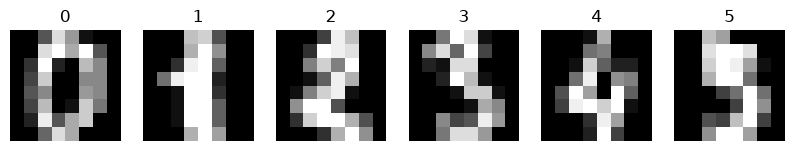

In [17]:
from sklearn.datasets import load_digits 
X, y = load_digits(return_X_y=True) # charger le jeu de données "digits" de sklearn, qui contient des images de chiffres manuscrits. Les images sont stockées dans la variable X et les étiquettes correspondantes (les chiffres) sont stockées dans la variable y.
n, p = X.shape # obtenir les dimensions du jeu de données X, où n est le nombre d'échantillons et p est le nombre de caractéristiques (pixels) pour chaque image.
print("X :", X.shape) # afficher les dimensions du jeu de données X

fig, axs = plt.subplots(1, 6, figsize=(10, 2)) # créer une figure avec 1 ligne et 6 colonnes pour afficher les images des chiffres manuscrits. 
for ax, img, lab in zip(axs, X[:6], y[:6]): # parcourir les axes, les images et les étiquettes des 6 premiers échantillons du jeu de données X et y.
    ax.imshow(img.reshape(8, 8), cmap="gray") # afficher l'image de chaque chiffre manuscrit en utilisant la fonction imshow avec une carte de couleurs en niveaux de gris.
    ax.set_title(str(lab)); ax.axis("off")# afficher le titre de chaque sous-graphique avec l'étiquette correspondante (le chiffre) et désactiver les axes pour une meilleure visualisation.
plt.show()# afficher le graphique final avec les images des chiffres manuscrits.

Xmean = X.mean(axis=0) # calculer la moyenne de chaque caractéristique (pixel) sur l'ensemble des échantillons du jeu de données X. 
Xc = X - Xmean  # centrer les données en soustrayant la moyenne de chaque caractéristique.

Le centrage (soustraction de la moyenne par colonne) est indispensable pour l'ACP : il place le nuage de points à l'origine, ce qui permet d'étudier uniquement les directions de variance.

### QN°2

In [18]:
Sigma = (Xc.T @ Xc) / (n - 1) # calculer la matrice de covariance empirique Sigma en multipliant la transposée de Xc par Xc, puis en divisant par (n - 1) pour obtenir une estimation non biaisée de la covariance.
vals, vecs = np.linalg.eigh(Sigma)   # calculer les valeurs propres et les vecteurs propres de la matrice Sigma 
idx = np.argsort(vals)[::-1] # trier les indices des valeurs propres dans l'ordre décroissant pour obtenir les composantes principales dans l'ordre de leur importance.
vals = vals[idx]
vecs = vecs[:, idx]  # afficher les vecteurs propres correspondants aux valeurs propres triées, où chaque colonne de vecs représente une composante principale.

print("Σ symétrique ?", np.allclose(Sigma, Sigma.T)) # vérifier si la matrice Sigma est symétrique en comparant Sigma avec sa transposée Sigma.T
print("5 plus grandes valeurs propres :", np.round(vals[:5], 3)) # afficher les 5 plus grandes valeurs propres de la matrice Sigma

Σ symétrique ? True
5 plus grandes valeurs propres : [179.007 163.718 141.788 101.1    69.513]


pourquoi eigh et pas eig : Σ est symétrique réelle par construction. eigh exploite cette structure : valeurs propres garanties réelles, vecteurs propres orthonormés, complexité 2× plus faible et stabilité numérique meilleure. eig peut renvoyer des valeurs complexes par erreur d'arrondi et des vecteurs non orthogonaux.

### QN°3

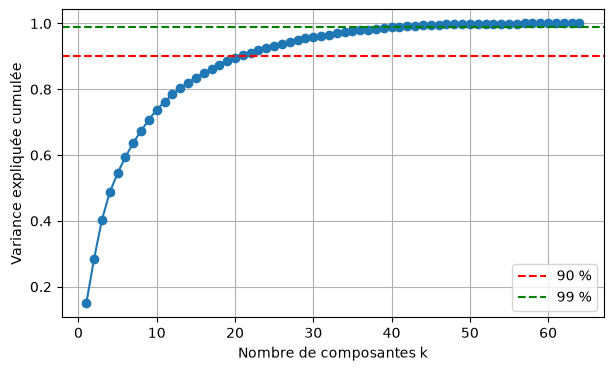

90 % atteint à k = 21 composantes
99 % atteint à k = 41 composantes


In [19]:
var_cum = np.cumsum(vals) / vals.sum() # calculer la variance expliquée cumulée en sommant les valeurs propres triées et en les normalisant par la somme totale des valeurs propres

plt.figure(figsize=(7,4)) # créer une figure pour tracer la variance expliquée cumulée en fonction du nombre de composantes principales
plt.plot(range(1, p+1), var_cum, "o-")# tracer la variance expliquée cumulée en fonction du nombre de composantes principales (k) avec des points et des lignes
plt.axhline(0.9, color="r", ls="--", label="90 %") # tracer une ligne horizontale à 90 % de variance expliquée cumulée pour indiquer le seuil de variance souhaité
plt.axhline(0.99, color="g", ls="--", label="99 %")# tracer une ligne horizontale à 99 % de variance expliquée cumulée pour indiquer un autre seuil de variance souhaité
plt.xlabel("Nombre de composantes k") # tracer l'étiquette de l'axe x pour indiquer le nombre de composantes principales (k)
plt.ylabel("Variance expliquée cumulée")# tracer l'étiquette de l'axe y pour indiquer la variance expliquée cumulée
plt.legend(); plt.grid(True); plt.show() # afficher la légende, la grille et le graphique final pour visualiser la variance expliquée cumulée en fonction du nombre de composantes principales.

for seuil in (0.90, 0.99):# itérer sur les seuils de variance expliquée cumulée souhaités (90 % et 99 %)
    k = np.searchsorted(var_cum, seuil) + 1
    print(f"{seuil*100:.0f} % atteint à k = {k} composantes")

Quelques dizaines de composantes suffisent à capter 90 % de l'information (les pixels sont très corrélés) ; il en faut une vingtaine de plus pour atteindre 99 %, ce qui montre que l'essentiel de la variance est porté par un petit sous-espace.

### QN°4

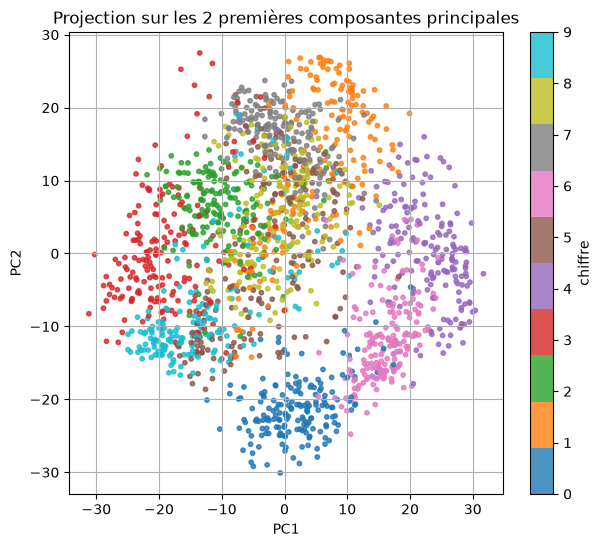

In [20]:
V2 = vecs[:, :2] # sélectionner les deux premières composantes principales (vecteurs propres) pour la projection des données centrées Xc sur un espace bidimensionnel.
Z = Xc @ V2 # projeter les données centrées Xc sur les deux premières composantes principales en multipliant Xc par la matrice V2. 

plt.figure(figsize=(7,6)) # créer une figure pour visualiser la projection des données sur les deux premières composantes principales
sc = plt.scatter(Z[:,0], Z[:,1], c=y, cmap="tab10", s=10, alpha=0.8)# tracer un nuage de points (scatter plot) des données projetées Z sur les deux premières composantes principales
plt.colorbar(sc, label="chiffre") # afficher une barre de couleur pour indiquer la correspondance entre les couleurs des points et les chiffres représentés par les étiquettes y
plt.xlabel("PC1"); plt.ylabel("PC2")# tracer les étiquettes des axes x et y 
plt.title("Projection sur les 2 premières composantes principales")# tracer le titre du graphique
plt.grid(True); plt.show() # afficher la grille et le graphique final

Certains chiffres se séparent nettement (typiquement 0, 6 et 1 d'un côté ; 3, 8, 9 se recouvrent davantage car ils partagent beaucoup de traits). Deux dimensions ne suffisent donc pas à séparer les 10 classes, mais l'ACP révèle déjà une organisation claire.

### QN°5

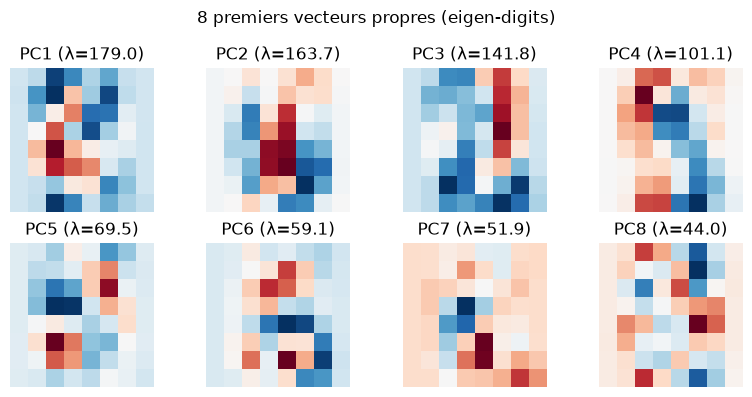

In [21]:
fig, axs = plt.subplots(2, 4, figsize=(8, 4)) # créer une figure avec 2 lignes et 4 colonnes pour afficher les 8 premiers vecteurs propres (eigen-digits) 
for k, ax in enumerate(axs.ravel()):# itérer sur les indices des 8 premiers vecteurs propres et les axes correspondants pour afficher chaque vecteur propre sous forme d'image
    ax.imshow(vecs[:, k].reshape(8, 8), cmap="RdBu_r") # afficher le k-ième vecteur propre sous forme d'image en utilisant la fonction imshow avec une carte de couleurs "RdBu_r" (rouge-bleu inversé)
    ax.set_title(f"PC{k+1} (λ={vals[k]:.1f})")# afficher le titre de chaque sous-graphique avec le numéro de la composante principale (PCk) et la valeur propre correspondante (λ)
    ax.axis("off") # désactiver les axes pour une meilleure visualisation des vecteurs propres
plt.suptitle("8 premiers vecteurs propres (eigen-digits)")# tracer le titre principal de la figure 
plt.tight_layout(); plt.show()# afficher la figure finale avec les 8 premiers vecteurs propres (eigen-digits) 

Les premiers vecteurs propres ressemblent à des « motifs de base » : PC1 capture un contraste global clair/foncé, PC2 un contraste horizontal/vertical, les suivants des détails locaux (boucles, barres). Les derniers vecteurs propres, associés à de petites valeurs propres, ressemblent à du bruit.

### QN°6

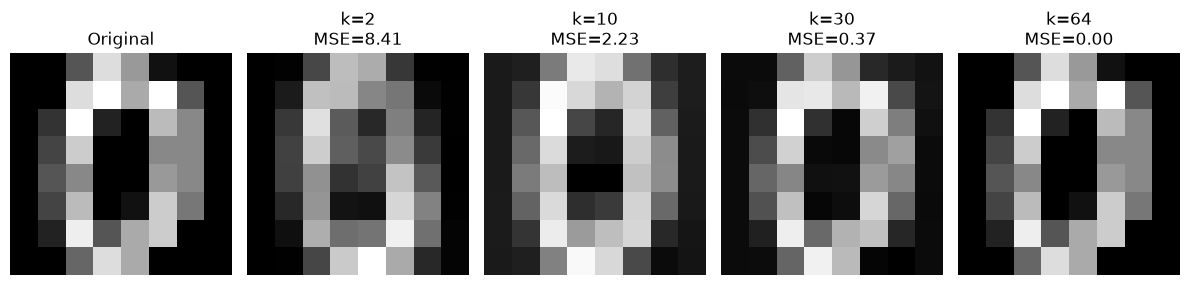

In [22]:
def reconstruire(x_centre, Qk):# reconstruire une image à partir de ses coordonnées centrées x_centre et des k premières composantes principales Qk
    return Xmean + x_centre @ Qk @ Qk.T # reconstruire l'image en ajoutant la moyenne des caractéristiques (pixels) de l'image x_centre projetée sur les k premières composantes principales Qk et en multipliant par la transposée de Qk pour revenir à l'espace original des pixels.

idx_img = 0 
x = X[idx_img] # sélectionner l'image à reconstruire à partir du jeu de données X en utilisant l'indice idx_img
xc = Xc[idx_img] # centrer l'image sélectionnée en soustrayant la moyenne des caractéristiques (pixels) de l'image x

fig, axs = plt.subplots(1, 5, figsize=(12, 3)) # créer une figure avec 1 ligne et 5 colonnes 
axs[0].imshow(x.reshape(8,8), cmap="gray")# afficher l'image originale de l'image sélectionnée en utilisant la fonction imshow avec une carte de couleurs en niveaux de gris
axs[0].set_title("Original"); axs[0].axis("off")# afficher le titre du sous-graphique 

for ax, k in zip(axs[1:], [2, 10, 30, 64]): # itérer sur les axes restants et les valeurs de k (nombre de composantes principales) pour reconstruire l'image à partir des k premières composantes principales
    Qk = vecs[:, :k] # sélectionner les k premières composantes principales (vecteurs propres) pour la reconstruction de l'image
    xr = reconstruire(xc, Qk)# reconstruire l'image à partir des coordonnées centrées xc et des k premières composantes principales Qk
    mse = np.mean((x - xr)**2)# calculer l'erreur quadratique moyenne (MSE) entre l'image originale x et l'image reconstruite xr pour évaluer la qualité de la reconstruction
    ax.imshow(xr.reshape(8,8), cmap="gray")# afficher l'image reconstruite à partir des k premières composantes principales en utilisant la fonction imshow avec une carte de couleurs en niveaux de gris
    ax.set_title(f"k={k}\nMSE={mse:.2f}"); ax.axis("off") # afficher le titre du sous-graphique avec le nombre de composantes principales k et l'erreur quadratique moyenne (MSE) correspondante, et désactiver les axes pour une meilleure visualisation.
plt.tight_layout(); plt.show() # afficher la figure finale avec les images reconstruites à partir des k premières composantes principales et les erreurs quadratiques moyennes (MSE) correspondantes.

L'erreur quadratique moyenne décroît fortement dès k = 10 et devient quasi nulle à k = 64 (reconstruction exacte). Cela illustre le compromis compression/fidélité : on peut représenter chaque image 8×8 par quelques coordonnées seulement en conservant l'essentiel de l'information visuelle.

### QN°7

In [23]:
from sklearn.decomposition import PCA

pca = PCA(n_components=p)            # toutes les composantes
Zp_full = pca.fit_transform(Xc)      # (1797, 64)
Z_full  = Xc @ vecs                  # (1797, 64) — PCA "à la main"
Vp      = pca.components_.T          # (64, 64)

print("Valeurs propres identiques ?",
      np.allclose(pca.explained_variance_, vals, atol=1e-8))#afficher si les valeurs propres calculées par la méthode PCA de sklearn sont proches de celles calculées "à la main" à partir de la matrice de covariance Sigma, en tenant compte d'une tolérance spécifiée (atol=1e-8).

print("Vecteurs identiques à ±1 près ?",
      np.allclose(np.abs(Vp), np.abs(vecs), atol=1e-6)) #afficher si les vecteurs propres calculés par la méthode PCA de sklearn sont proches de ceux calculés "à la main" à partir de la matrice de covariance Sigma, en tenant compte d'un facteur de signe (±1) et d'une tolérance spécifiée (atol=1e-6).

print("Projections (64 comp.) identiques à ±1 près ?",
      np.allclose(np.abs(Zp_full), np.abs(Z_full), atol=1e-6)) # afficher si les projections des données centrées Xc sur les 64 composantes principales calculées par la méthode PCA de sklearn sont proches de celles calculées "à la main" à partir des vecteurs propres, en tenant compte d'un facteur de signe (±1) et d'une tolérance spécifiée (atol=1e-6).

print("Projections (2 premières comp.) identiques à ±1 près ?",
      np.allclose(np.abs(Zp_full[:, :2]), np.abs(Z[:, :2]), atol=1e-6))#afficher si les projections des données centrées Xc sur les 2 premières composantes principales calculées par la méthode PCA de sklearn sont proches de celles calculées "à la main" à partir des vecteurs propres, en tenant compte d'un facteur de signe (±1) et d'une tolérance spécifiée (atol=1e-6).

Valeurs propres identiques ? True
Vecteurs identiques à ±1 près ? True
Projections (64 comp.) identiques à ±1 près ? True
Projections (2 premières comp.) identiques à ±1 près ? True


pourquoi le signe peut différer : Un vecteur propre v et son opposé −v définissent la même direction propre : ils sont tous deux solutions de Σv = λv. L'algorithme (eigh, SVD interne de sklearn, LAPACK…) choisit arbitrairement l'orientation, d'où un signe ± aléatoire selon l'implémentation. C'est pourquoi on compare |V| et non V directement.